# D05 · Ranking quality is not an alert policy

Visualize three seeds, distinguish average precision from threshold decisions, and estimate how prevalence changes the number of false alerts.

**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).

**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence

Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D05", SNAPSHOT_PATH)

D05 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/tabular/local-s41-20261026T163036Z-3c6401 | recorded: 20261026T163036Z | seed: 41
Run: artifacts/tabular/local-s42-20261026T163041Z-2b586b | recorded: 20261026T163041Z | seed: 42
Run: artifacts/tabular/local-s43-20261026T163045Z-2328af | recorded: 20261026T163045Z | seed: 43


## The concept

A supervised predictor estimates an outcome from structured features. Average precision (AP) summarizes precision over recall changes as the score threshold moves; the constant-prior baseline's AP is prevalence. A fixed threshold creates a separate operational policy.

The original data has chronological splits, stochastic labels and future drift. Selection used validation data with a 5% false-positive budget; future-period test outcomes were reported without adjusting the threshold.

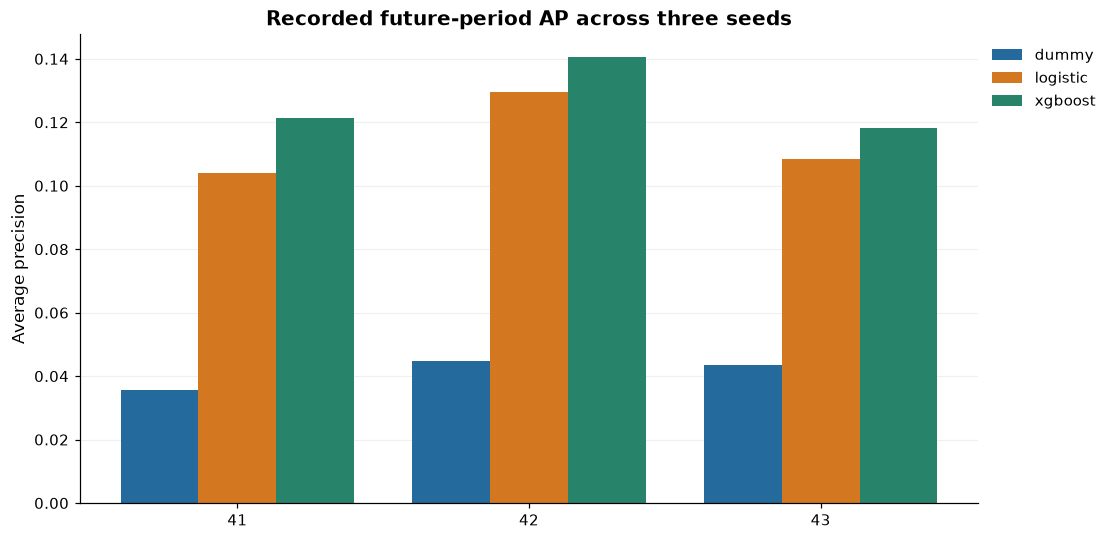

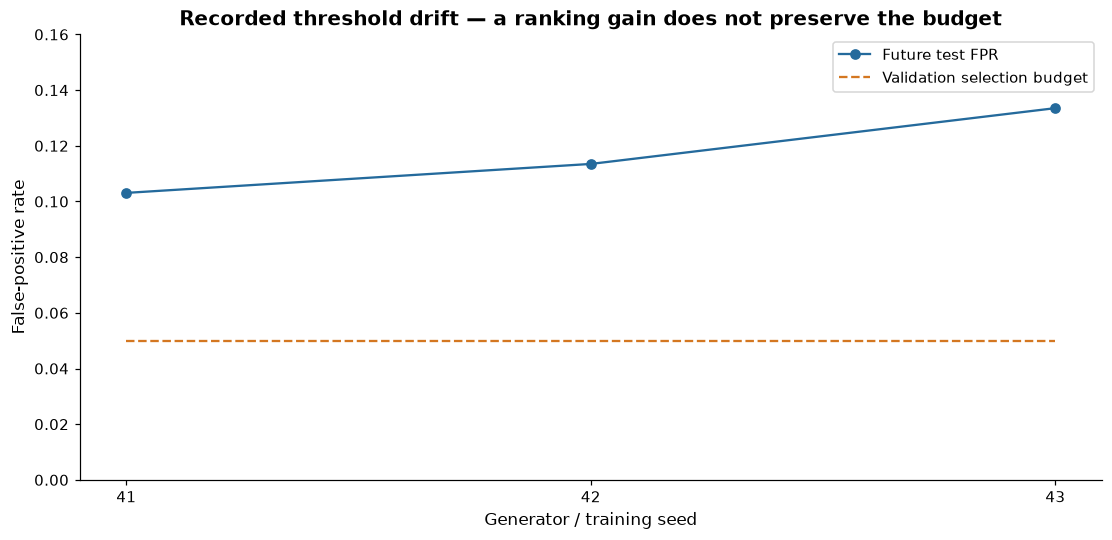

In [2]:
runs = d['runs']
seeds = [str(r['seed']) for r in runs]
grouped_bars(seeds, {model: [r['metrics'][model]['pr_auc_average_precision'] for r in runs]
                    for model in ['dummy', 'logistic', 'xgboost']},
             title='Recorded future-period AP across three seeds', ylabel='Average precision', fraction=False)
plt.show()
fig, ax = plt.subplots(layout='constrained')
ax.plot(seeds, [r['metrics']['xgboost']['false_positive_rate'] for r in runs], 'o-', label='Future test FPR')
ax.plot(seeds, [r['selection']['fpr_budget'] for r in runs], '--', label='Validation selection budget')
ax.set(ylim=(0, .16), ylabel='False-positive rate', xlabel='Generator / training seed',
       title='Recorded threshold drift — a ranking gain does not preserve the budget')
ax.legend(); plt.show()

### Change prevalence, holding conditional error rates fixed
This is an **illustrative planning calculation** using the recorded seed-41 recall and FPR. Holding those rates fixed under a prevalence change is an assumption, not a validated drift model. Expected true alerts are `N × prevalence × recall`; false alerts are `N × (1 − prevalence) × FPR`.

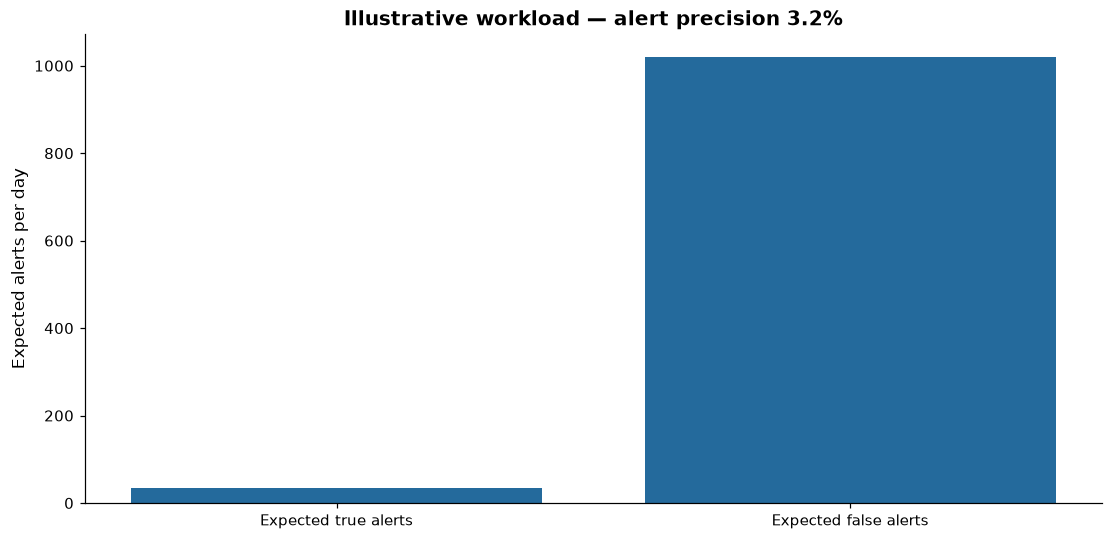

In [3]:
daily_requests = 10000
assumed_prevalence = 0.01  # Try .001, .0357 or .10.
metrics = next(r for r in runs if r['seed'] == 41)['metrics']['xgboost']
true_alerts = daily_requests * assumed_prevalence * metrics['recall']
false_alerts = daily_requests * (1 - assumed_prevalence) * metrics['false_positive_rate']
precision = true_alerts / (true_alerts + false_alerts)
fig, ax = plt.subplots(layout='constrained')
ax.bar(['Expected true alerts', 'Expected false alerts'], [true_alerts, false_alerts])
ax.set(title=f'Illustrative workload — alert precision {precision:.1%}', ylabel='Expected alerts per day')
plt.show()

**Interpretation check:** lowering the threshold generally raises recall and false alerts; it does not improve the score ranking and therefore does not directly change AP. The three seeds show generator variability, not a confidence interval over real customers. Production work needs representative labels, calibrated scores and an explicit cost of each kind of error.

## What you learned and when to use it

Use supervised tabular models when decision-time features and labels support prediction. Compare a prior, logistic regression and interpretable alternatives before adding complexity. Unsupervised outlier detection answers a different question: unusualness is not the probability of a harmful outcome.

**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d05--predict-from-tabular-features).

**Train or run the actual model:** follow the [D05 tutorial](../docs/CPU_DEMOS.md#d05-learn-a-tabular-risk-function). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.

[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)